# Telecom Customer Churn: Prediction and Retention Targeting

Which customers are about to cancel, and why? This notebook predicts churn for 7,043 telecom customers, explains the predictions with SHAP, and estimates how much a retention campaign aimed at the model's top-risk customers would save compared with contacting customers at random.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report
from xgboost import XGBClassifier

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Data

IBM's Telco Customer Churn sample: one row per customer with demographics, services, contract and billing details, and whether they left in the last month.

In [2]:
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(URL)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df.shape, "| missing TotalCharges:", df["TotalCharges"].isna().sum())
df["TotalCharges"] = df["TotalCharges"].fillna(0)   # brand-new customers, tenure 0
df["Churn"] = (df["Churn"] == "Yes").astype(int)
print(f"churn rate: {df['Churn'].mean():.1%}")
df.head()

(7043, 21) | missing TotalCharges: 11
churn rate: 26.5%


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


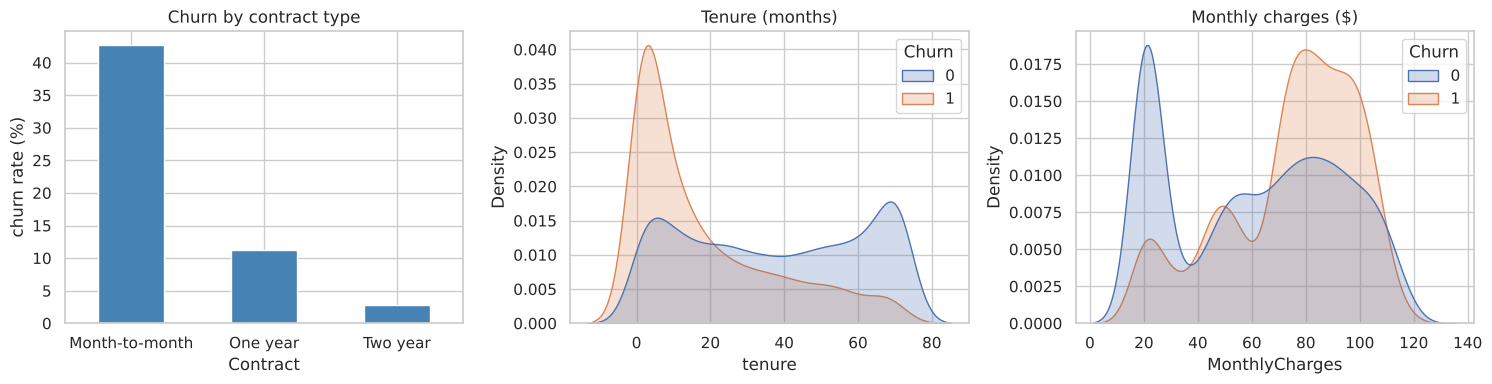

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
(df.groupby("Contract")["Churn"].mean() * 100).plot.bar(ax=ax[0], color="steelblue", rot=0)
ax[0].set_ylabel("churn rate (%)"); ax[0].set_title("Churn by contract type")
sns.kdeplot(data=df, x="tenure", hue="Churn", common_norm=False, fill=True, ax=ax[1]); ax[1].set_title("Tenure (months)")
sns.kdeplot(data=df, x="MonthlyCharges", hue="Churn", common_norm=False, fill=True, ax=ax[2]); ax[2].set_title("Monthly charges ($)")
plt.tight_layout(); plt.savefig("images/eda.png", dpi=120); plt.show()
(df.groupby("Contract")["Churn"].mean() * 100).round(1)

## 2. Models

In [4]:
y = df["Churn"]
X = df.drop(columns=["customerID", "Churn"])
num = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
cat = [c for c in X.columns if c not in num]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

pre = ColumnTransformer([("num", StandardScaler(), num),
                         ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), cat)])
models = {
    "Logistic regression": Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=2000, C=0.5))]),
    "XGBoost": Pipeline([("pre", pre), ("clf", XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                          subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE))]),
}
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
rows, probs = [], {}
for name, m in models.items():
    cv_auc = cross_val_score(m, X_train, y_train, cv=cv, scoring="roc_auc").mean()
    m.fit(X_train, y_train)
    probs[name] = m.predict_proba(X_test)[:, 1]
    rows.append({"model": name, "CV ROC-AUC": cv_auc, "Test ROC-AUC": roc_auc_score(y_test, probs[name]),
                 "Test PR-AUC": average_precision_score(y_test, probs[name])})
pd.DataFrame(rows).set_index("model").round(3)

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC
model,,,
Logistic regression,0.846,0.842,0.635
XGBoost,0.847,0.845,0.664


The two models score almost the same. Logistic regression is simpler to explain and deploy, but XGBoost with SHAP gives per-customer explanations, which retention agents can use in a call.

In [5]:
best = "XGBoost"
print(classification_report(y_test, (probs[best] >= 0.5).astype(int), target_names=["stay", "churn"], digits=3))

              precision    recall  f1-score   support

        stay      0.843     0.906     0.873      1035
       churn      0.672     0.532     0.594       374

    accuracy                          0.807      1409
   macro avg      0.758     0.719     0.734      1409
weighted avg      0.798     0.807     0.799      1409



## 3. Why customers leave (SHAP)

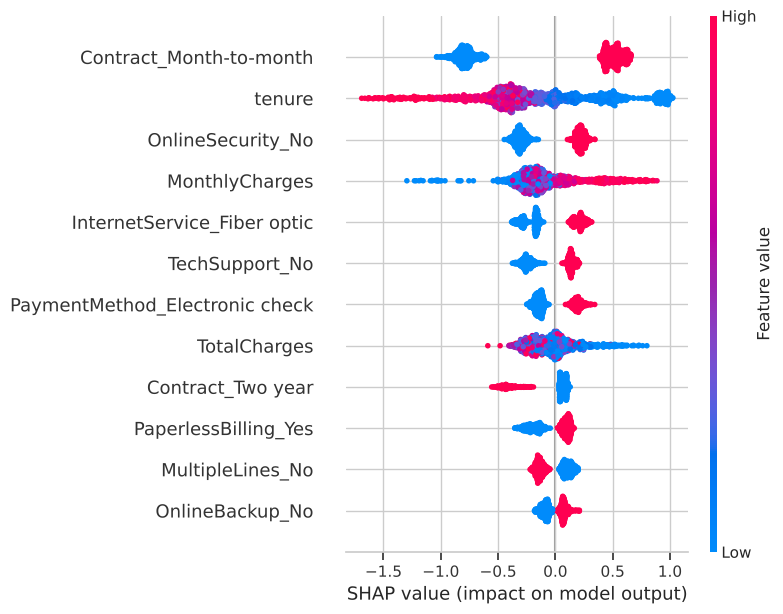

In [6]:
xgb_pipe = models["XGBoost"]
Xt = xgb_pipe.named_steps["pre"].transform(X_test)
names = xgb_pipe.named_steps["pre"].get_feature_names_out()
names = [n.split("__", 1)[1] for n in names]
Xt = pd.DataFrame(Xt.toarray() if hasattr(Xt, "toarray") else Xt, columns=names)
explainer = shap.TreeExplainer(xgb_pipe.named_steps["clf"])
sv = explainer.shap_values(Xt)
shap.summary_plot(sv, Xt, max_display=12, show=False)
plt.tight_layout(); plt.savefig("images/shap_summary.png", dpi=120, bbox_inches="tight"); plt.show()

predicted churn probability: 0.93


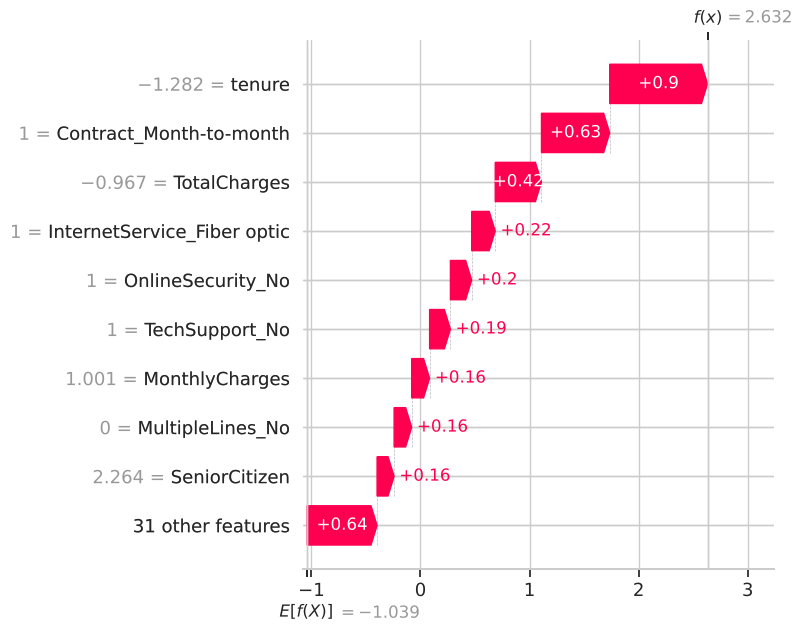

In [7]:
# One high-risk customer, explained
i = int(np.argmax(probs[best]))
print(f"predicted churn probability: {probs[best][i]:.2f}")
shap.plots.waterfall(shap.Explanation(sv[i], base_values=float(np.ravel(explainer.expected_value)[0]),
                     data=Xt.iloc[i].values, feature_names=names), max_display=10, show=False)
plt.tight_layout(); plt.savefig("images/shap_one_customer.png", dpi=120, bbox_inches="tight"); plt.show()

## 4. Is a targeted retention campaign worth it?

Example assumptions (to be replaced with the company's real figures):
- An offer costs **$50** per contacted customer.
- A churner who receives the offer stays **30%** of the time.
- A retained customer is worth **12 months** of their current monthly charge.

The chart compares contacting the top-k customers ranked by the model with contacting k customers at random.

best campaign size: top 660 customers (47% of base)
net value with model targeting: $52,413
net value contacting the same number at random: $13,096


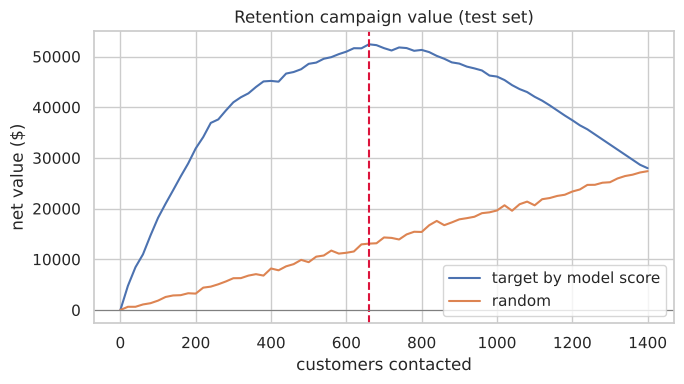

In [8]:
OFFER, SAVE_RATE, MONTHS = 50, 0.30, 12
test = X_test.assign(churn=y_test.values, p=probs[best])
value = test["MonthlyCharges"] * MONTHS

def profit(order, k):
    idx = order[:k]
    gain = (test["churn"].values[idx] * value.values[idx] * SAVE_RATE).sum()
    return gain - OFFER * k

order_model = np.argsort(-test["p"].values)
rng = np.random.default_rng(RANDOM_STATE)
ks = np.arange(0, len(test) + 1, 20)
model_curve = [profit(order_model, k) for k in ks]
random_curve = [np.mean([profit(rng.permutation(len(test)), k) for _ in range(20)]) for k in ks]

best_k = ks[int(np.argmax(model_curve))]
print(f"best campaign size: top {best_k} customers ({best_k / len(test):.0%} of base)")
print(f"net value with model targeting: ${max(model_curve):,.0f}")
print(f"net value contacting the same number at random: ${random_curve[int(np.argmax(model_curve))]:,.0f}")

plt.figure(figsize=(7, 4))
plt.plot(ks, model_curve, label="target by model score"); plt.plot(ks, random_curve, label="random")
plt.axvline(best_k, ls="--", c="crimson"); plt.axhline(0, c="grey", lw=0.8)
plt.xlabel("customers contacted"); plt.ylabel("net value ($)"); plt.title("Retention campaign value (test set)")
plt.legend(); plt.tight_layout(); plt.savefig("images/campaign_value.png", dpi=120); plt.show()

## Takeaways

- Month-to-month contracts, short tenure, high monthly charges and fiber internet service are the strongest churn signals. Month-to-month customers churn at 42.7%, two-year customers at 2.8%.
- Customers on electronic check and those without tech support or online security churn more, which points to specific offers (auto-pay discounts, bundled support) rather than a generic discount.
- Contacting the 660 highest-risk customers in the test set returns about $52,000 net, four times what the same number of random contacts would return (about $13,000). The best campaign size depends on the offer cost and save rate, so those assumptions should be checked with the retention team.